# 02 — Entrenamiento en Google Colab GPU (Fase 3: Jueces + Pretrain Pix2Pix)

Este notebook ejecuta en GPU (**Entorno de ejecución → Cambiar tipo de entorno → T4 GPU**):
1. Montaje de **Google Drive** para persistir `checkpoints/`, `results/` y `figuras/`.
2. Clonación / actualización del repositorio `handwritten-font-cgan`.
3. Generación reproducible del dataset sintético (`SEED = 42`).
4. Entrenamiento de los clasificadores jueces congelables (**ResNet-18** y **EfficientNet-B0**).
5. Preentrenamiento de **Pix2Pix (U-Net + PatchGAN)** sobre pares sintéticos.
6. Verificación visual y cuantitativa del **Checkpoint 3**.

In [2]:
# 1. Verificar GPU y montar Google Drive
from pathlib import Path
import torch
from google.colab import drive

print("PyTorch:", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ADVERTENCIA: No hay GPU activa. Activa GPU en Entorno de ejecución -> Cambiar tipo de entorno.")

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/handwritten-font-cgan")
CKPT_DIR = DRIVE_ROOT / "checkpoints"
FIG_DIR = DRIVE_ROOT / "figuras"
RES_DIR = DRIVE_ROOT / "results"
for d in (CKPT_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Artefactos persistentes en:", DRIVE_ROOT)

Mounted at /content/drive
Artefactos persistentes en: /content/drive/MyDrive/handwritten-font-cgan


In [3]:
# 2. Clonar o actualizar el repositorio desde GitHub
import os
import subprocess

REPO_URL = "https://github.com/carloamezcua/handwritten-font-cgan.git"
REPO_DIR = Path("/content/handwritten-font-cgan")

if REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

os.chdir(REPO_DIR)
print("Directorio actual:", os.getcwd())

# Instalar solo librerías no incluidas por defecto en Colab (sin reinstalar PyTorch CUDA)
!pip install -q fonttools

Directorio actual: /content/handwritten-font-cgan


In [4]:
# 3. Generar dataset sintético en Colab (idéntico al local gracias a SEED=42)
if not Path("data/synthetic_pairs/metadata.csv").exists():
    !python -m src.data.03_generar_sinteticos --download-fonts
else:
    print("Dataset sintético ya existe en data/synthetic_pairs/")

[AVISO] No se pudo descargar ComingSoon-Regular.ttf desde https://raw.githubusercontent.com/google/fonts/main/ofl/comingsoon/ComingSoon-Regular.ttf: HTTP Error 404: Not Found
[AVISO] No se pudo descargar JustAnotherHand-Regular.ttf desde https://raw.githubusercontent.com/google/fonts/main/ofl/justanotherhand/JustAnotherHand-Regular.ttf: HTTP Error 404: Not Found
[AVISO] No se pudo descargar Schoolbell-Regular.ttf desde https://raw.githubusercontent.com/google/fonts/main/ofl/schoolbell/Schoolbell-Regular.ttf: HTTP Error 404: Not Found
Registro de licencias guardado en: data/fonts/licenses.csv (18 fuentes)
Fuente base limpia (x): data/fonts/base/Lato-Regular.ttf
Fuentes manuscritas válidas: 17 (train_fonts=14, val_fonts=3)
/content/handwritten-font-cgan/src/data/03_generar_sinteticos.py:252: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(x_img, mode="L").save(output_dir / x_rel)
/content/handwritten-font-cgan/src/data/03

In [5]:
# 4. Entrenar Jueces (ResNet-18 y EfficientNet-B0) con Early Stopping
!python -m src.train.train_judges \
    --model all \
    --data-dir data/synthetic_pairs \
    --checkpoints-dir "{CKPT_DIR}" \
    --figures-dir "{FIG_DIR}" \
    --results-dir "{RES_DIR / 'judges'}" \
    --epochs 30 \
    --batch-size 64 \
    --lr 1e-3 \
    --patience 7 \
    --num-workers 2 \
    --pretrained


=== Entrenando juez: resnet18 (pretrained=True, device=cuda) ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 178MB/s]
  Época 01/30 | train_loss=1.8986, train_acc=0.6073 | val_loss=1.3294, val_acc=0.7126, val_macro_f1=0.6728
  Época 02/30 | train_loss=0.7867, train_acc=0.9022 | val_loss=1.0635, val_acc=0.8252, val_macro_f1=0.8188
  Época 03/30 | train_loss=0.6702, train_acc=0.9273 | val_loss=1.0867, val_acc=0.7985, val_macro_f1=0.7865
  Época 04/30 | train_loss=0.6609, train_acc=0.9394 | val_loss=1.5042, val_acc=0.6830, val_macro_f1=0.6821
  Época 05/30 | train_loss=0.6317, train_acc=0.9387 | val_loss=1.0583, val_acc=0.7852, val_macro_f1=0.7752
  Época 06/30 | train_loss=0.5858, train_acc=0.9581 | val_loss=1.0922, val_acc=0.7941, val_macro_f1=0.7846
  Época 07/30 | train_loss=0.5450, train_acc=0.9625 | val_loss=1.0503, val_acc=0.8237, val_macro_f1=0.8121
  Época 08/3

resnet18         | época=23 | val_acc=0.8800 | val_macro_f1=0.8778 -> REVISAR (< 0.90)


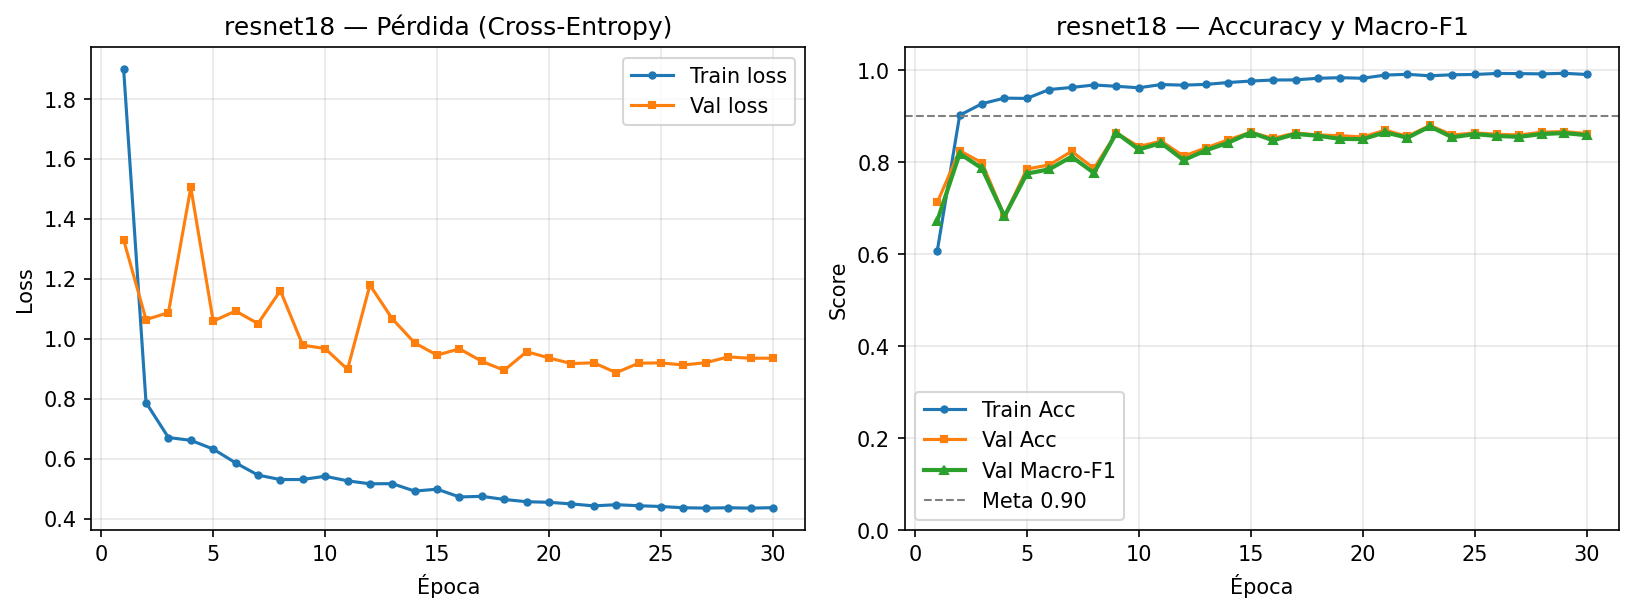

efficientnet_b0  | época=15 | val_acc=0.8533 | val_macro_f1=0.8520 -> REVISAR (< 0.90)


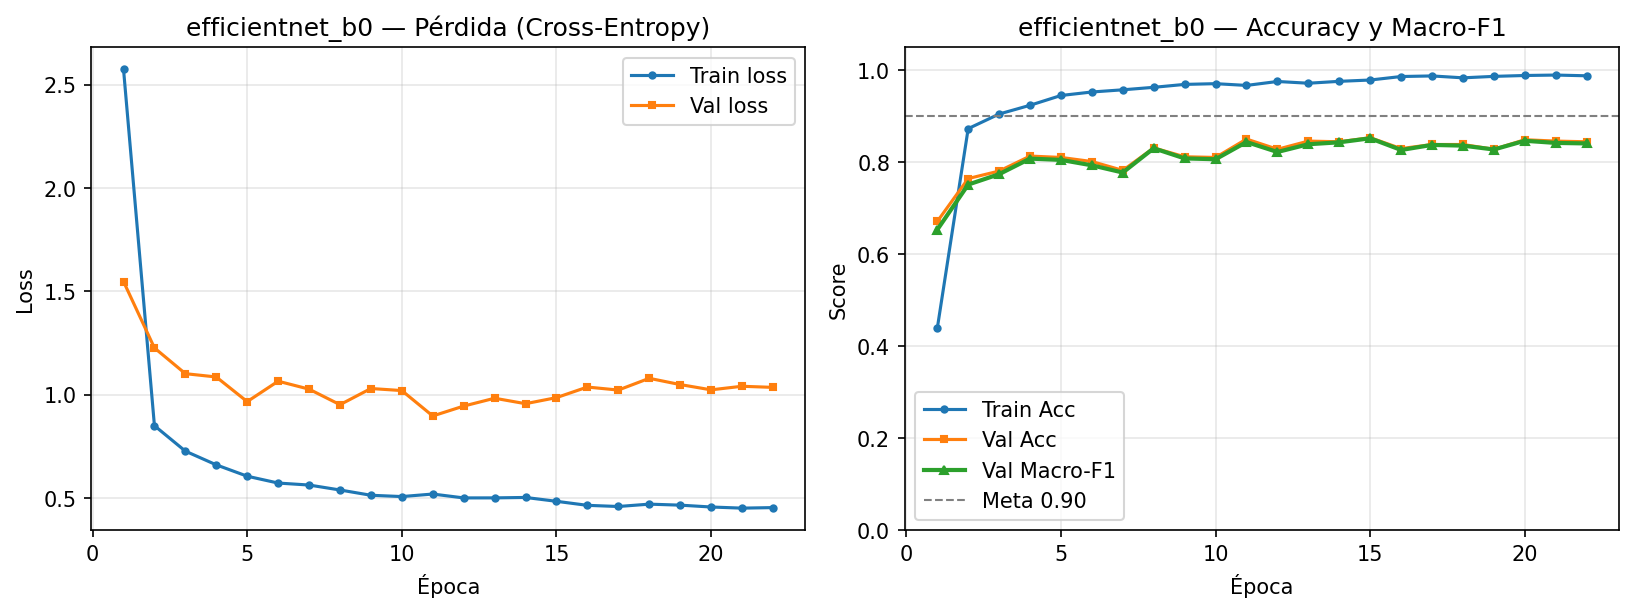

In [6]:
# 5. Checkpoint 3 (Parte A): Verificar que ambos jueces superan 90% Macro-F1
import json
from IPython.display import Image as IPyImage, display

for name in ("resnet18", "efficientnet_b0"):
    summary_path = RES_DIR / "judges" / f"judge_{name}_history.json"
    data = json.loads(summary_path.read_text(encoding="utf-8"))
    f1 = data["best_val_macro_f1"]
    acc = data["best_val_acc"]
    status = "OK (>= 0.90)" if f1 >= 0.90 else "REVISAR (< 0.90)"
    print(f"{name:16s} | época={data['best_epoch']:02d} | val_acc={acc:.4f} | val_macro_f1={f1:.4f} -> {status}")
    display(IPyImage(filename=str(FIG_DIR / f"train_judge_{name}.png")))

In [7]:
# 6. Preentrenar Pix2Pix sobre el dataset sintético (64 símbolos en train, 11 reservados en test_unseen)
!python -m src.train.train_pix2pix \
    --mode pretrain \
    --data-dir data/synthetic_pairs \
    --checkpoints-dir "{CKPT_DIR}" \
    --figures-dir "{FIG_DIR}" \
    --results-dir "{RES_DIR / 'pix2pix'}" \
    --epochs 60 \
    --batch-size 32 \
    --lr 2e-4 \
    --sample-every 10 \
    --num-workers 2


=== Entrenando Pix2Pix (mode=pretrain, epochs=60, batch_size=32, lr=0.0002, device=cuda) ===
  Época 001/060 | d_loss=0.3741 | g_adv=3.0380 | train_l1=0.3995 | val_l1=0.1379 | lr=2.00e-04
  Época 002/060 | d_loss=0.4279 | g_adv=2.2440 | train_l1=0.1203 | val_l1=0.1154 | lr=2.00e-04
  Época 003/060 | d_loss=0.4383 | g_adv=1.9239 | train_l1=0.1068 | val_l1=0.1143 | lr=2.00e-04
  Época 004/060 | d_loss=0.5130 | g_adv=1.5963 | train_l1=0.1049 | val_l1=0.1114 | lr=2.00e-04
  Época 005/060 | d_loss=0.5340 | g_adv=1.4061 | train_l1=0.1024 | val_l1=0.1116 | lr=2.00e-04
  Época 006/060 | d_loss=0.5480 | g_adv=1.3577 | train_l1=0.1015 | val_l1=0.1236 | lr=2.00e-04
  Época 007/060 | d_loss=0.5479 | g_adv=1.3241 | train_l1=0.1008 | val_l1=0.1156 | lr=2.00e-04
  Época 008/060 | d_loss=0.5409 | g_adv=1.3067 | train_l1=0.1002 | val_l1=0.1161 | lr=2.00e-04
  Época 009/060 | d_loss=0.5399 | g_adv=1.3040 | train_l1=0.1005 | val_l1=0.1154 | lr=2.00e-04
  Época 010/060 | d_loss=0.5452 | g_adv=1.3096 | tr


--- train_pix2pix_pretrain.png ---


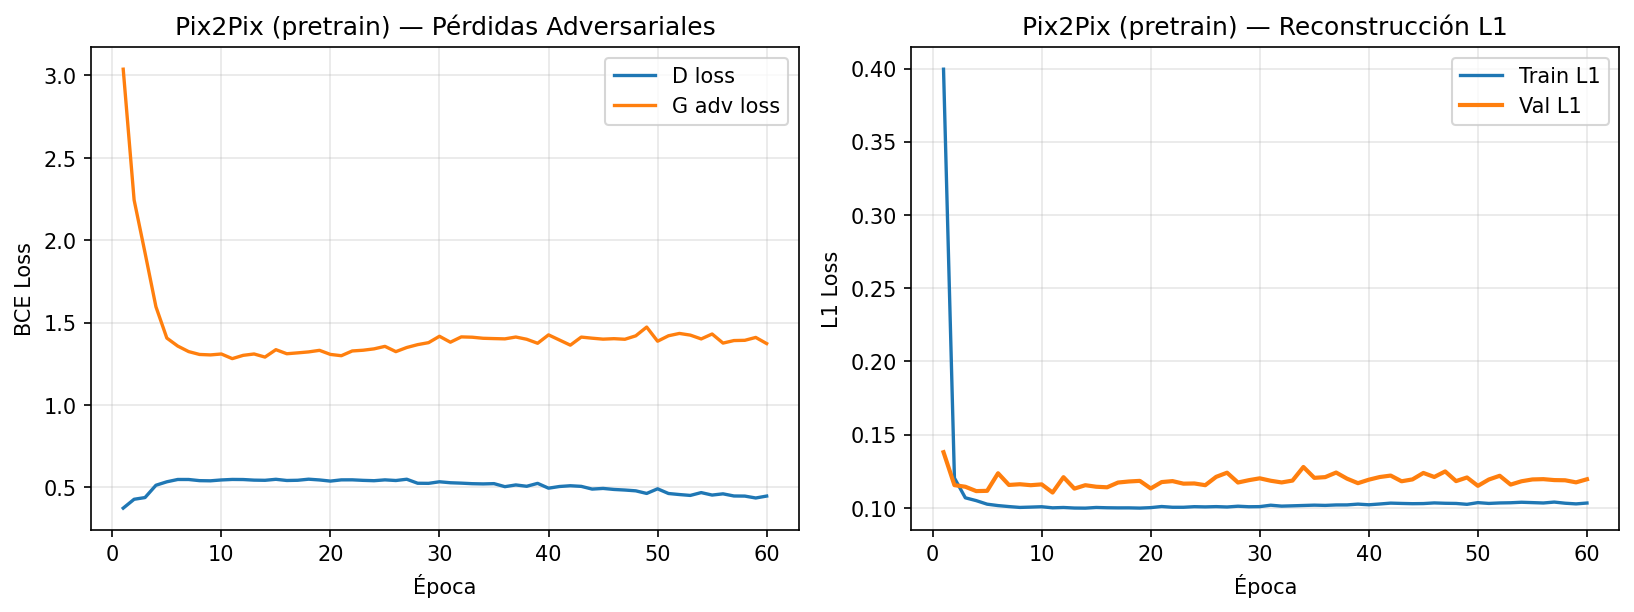


--- pix2pix_pretrain_val_grid.png ---


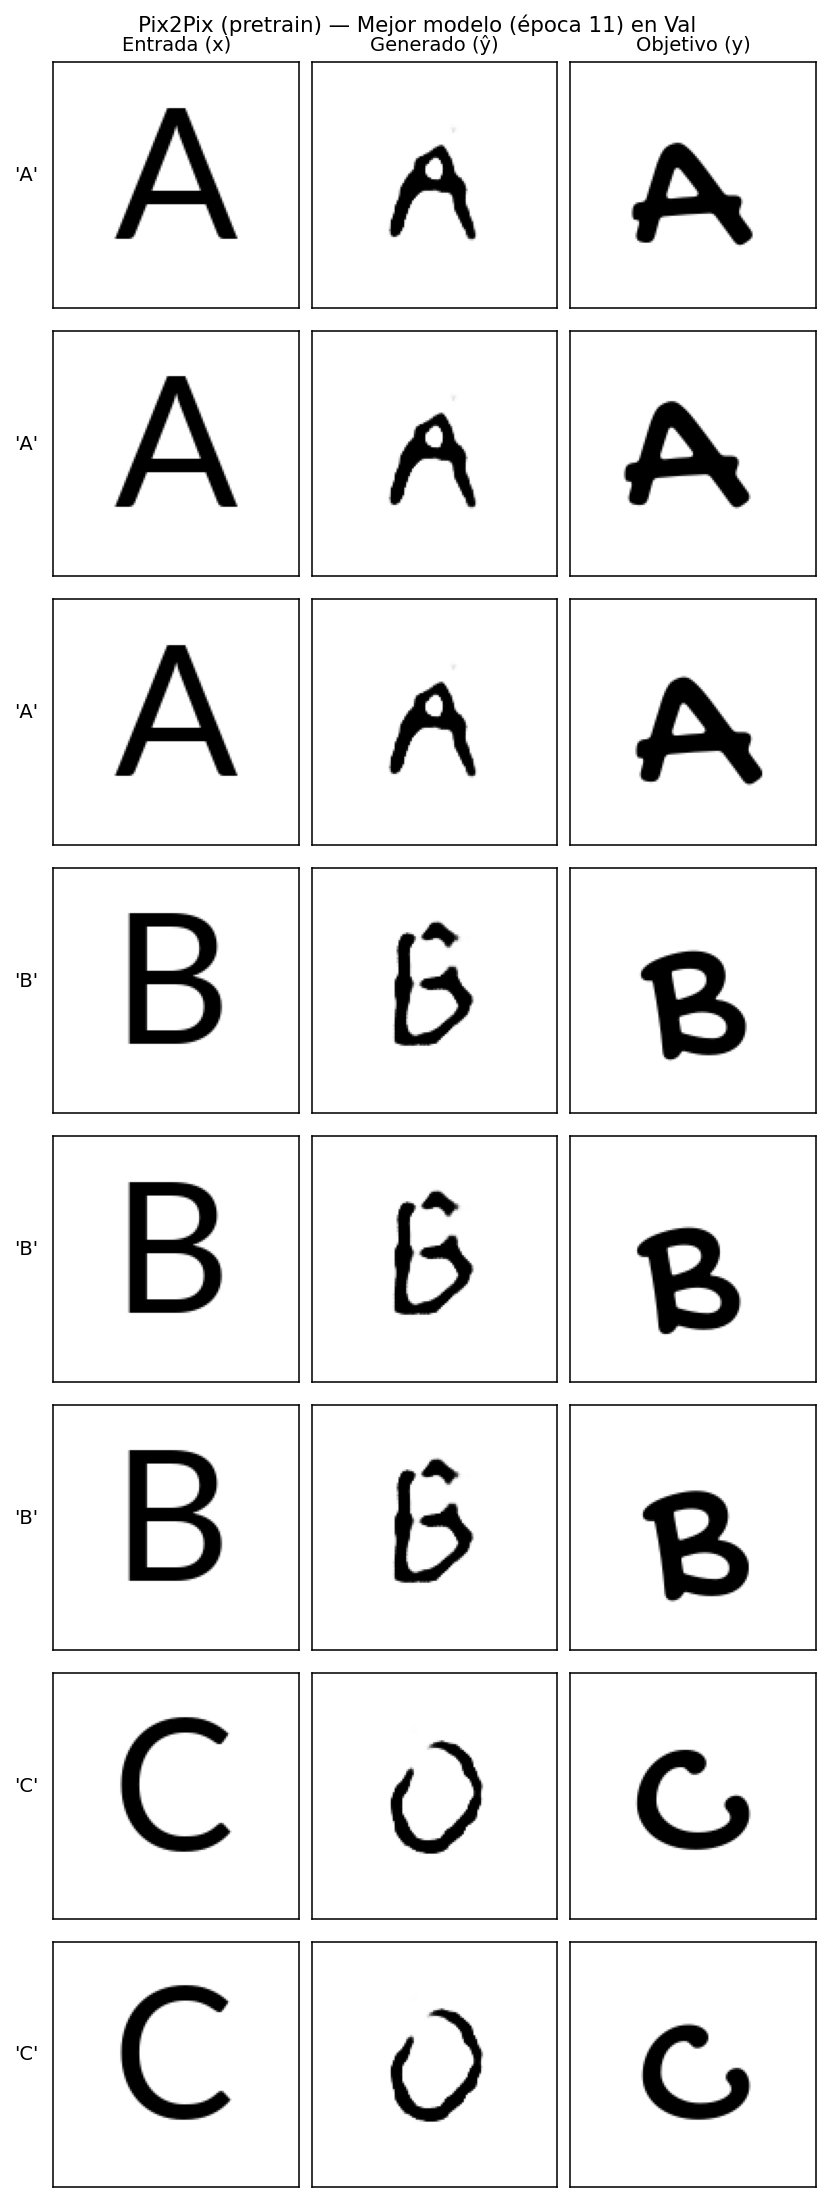


--- pix2pix_pretrain_unseen_grid.png ---


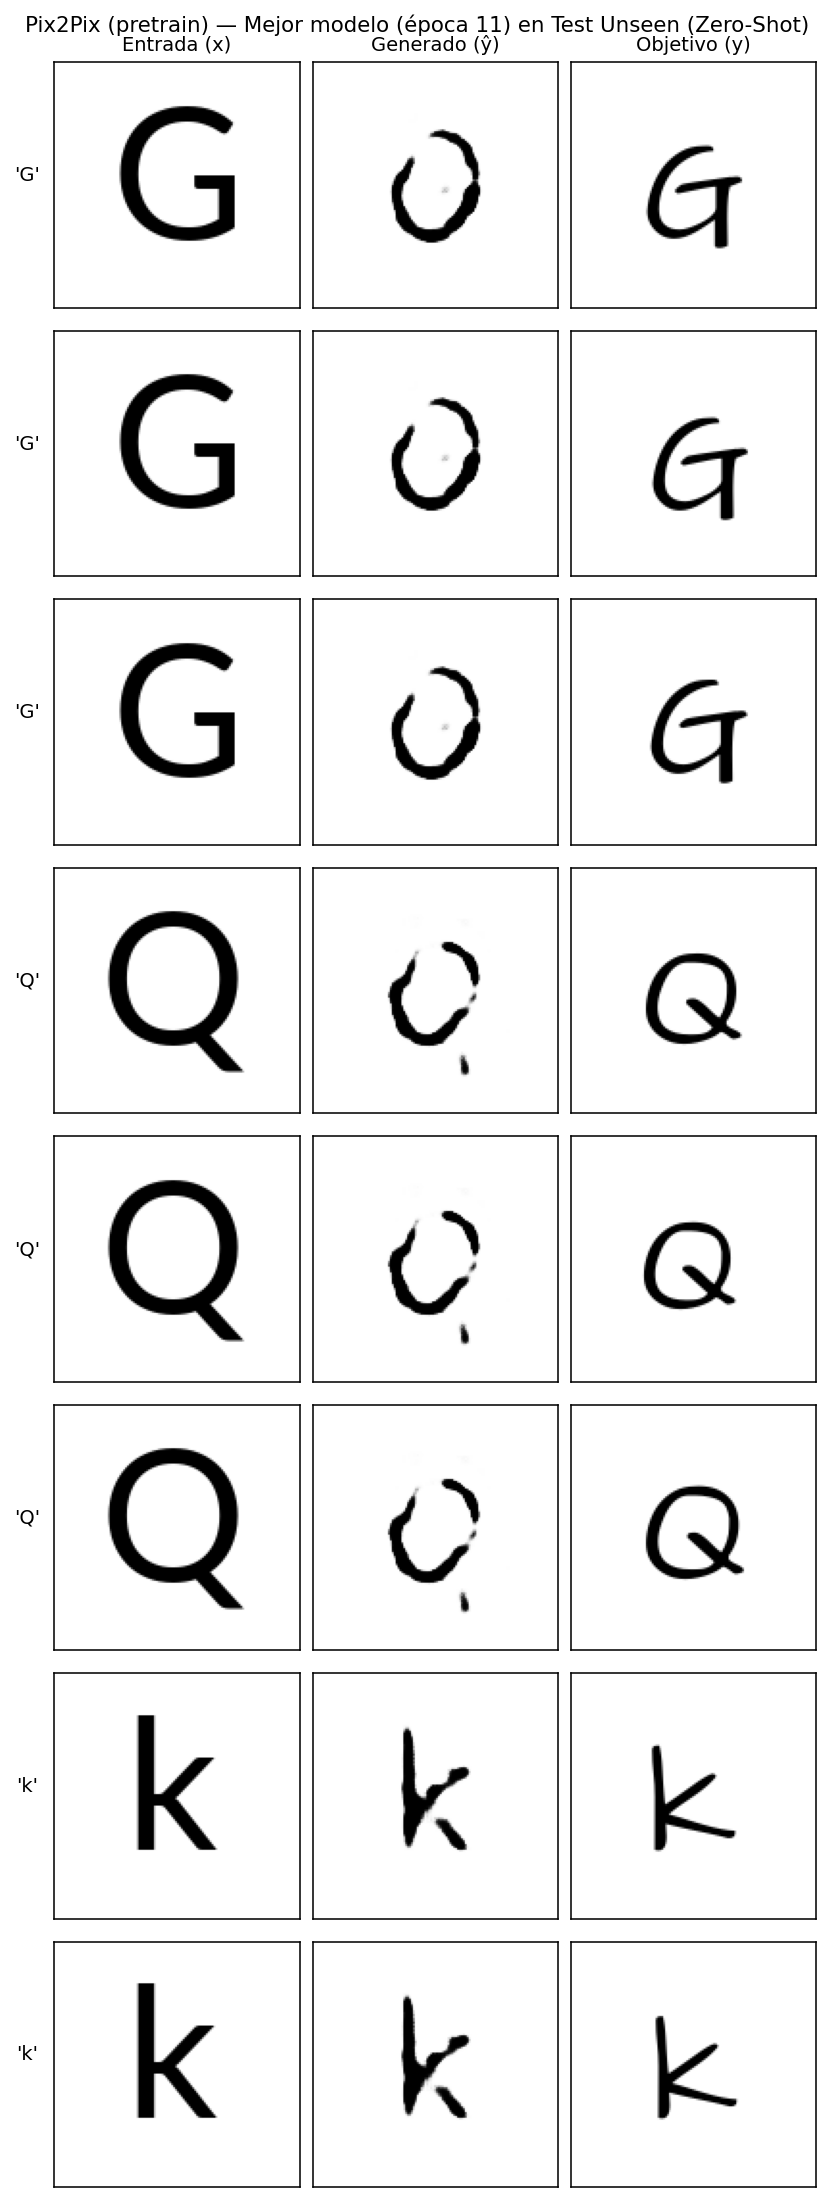

In [8]:
# 7. Checkpoint 3 (Parte B): Inspección visual de curvas y cuadrículas x | ŷ | y
for fname in (
    "train_pix2pix_pretrain.png",
    "pix2pix_pretrain_val_grid.png",
    "pix2pix_pretrain_unseen_grid.png",
):
    print(f"\n--- {fname} ---")
    display(IPyImage(filename=str(FIG_DIR / fname)))

In [9]:
import json, torch
from pathlib import Path

gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"Hardware: {gpu}\n")

runs = [
    ("ResNet-18 (Juez)", RES_DIR / "judges/judge_resnet18_history.json"),
    ("EfficientNet-B0 (Juez)", RES_DIR / "judges/judge_efficientnet_b0_history.json"),
    ("Pix2Pix (Pretrain)", RES_DIR / "pix2pix/pretrain/pix2pix_pretrain_history.json"),
]

print(f"{'Modelo':24s} | {'Épocas':6s} | {'Tiempo (s)':10s} | {'s/época':7s} | {'Peso (MB)':9s}")
print("-" * 70)
for label, path in runs:
    d = json.loads(path.read_text(encoding="utf-8"))
    hist = d["history"]
    epochs = len(next(iter(hist.values())))
    sec = d["elapsed_sec"]
    ckpt = Path(d.get("checkpoint_path") or d.get("best_checkpoint"))
    mb = ckpt.stat().st_size / (1024 ** 2) if ckpt.exists() else 0.0
    print(f"{label:24s} | {epochs:6d} | {sec:10.1f} | {sec/max(epochs,1):7.2f} | {mb:9.2f}")

Hardware: Tesla T4

Modelo                   | Épocas | Tiempo (s) | s/época | Peso (MB)
----------------------------------------------------------------------
ResNet-18 (Juez)         |     30 |       99.9 |    3.33 |     42.84
EfficientNet-B0 (Juez)   |     22 |      117.3 |    5.33 |     15.95
Pix2Pix (Pretrain)       |     60 |      832.6 |   13.88 |    170.16


## Siguiente paso al terminar en Colab
1. Desde tu Google Drive (`MyDrive/handwritten-font-cgan/checkpoints/`), descarga a tu carpeta local `checkpoints/`:
   - `judge_resnet18.pth`
   - `judge_efficientnet_b0.pth`
   - `pix2pix_pretrained.pth`
2. Desde `MyDrive/handwritten-font-cgan/figuras/`, copia a tu carpeta local `docs/figuras/`:
   - `train_judge_resnet18.png`, `train_judge_efficientnet_b0.png`
   - `train_pix2pix_pretrain.png`, `pix2pix_pretrain_val_grid.png`, `pix2pix_pretrain_unseen_grid.png`
3. Haz `git add docs/figuras/` y commit de las gráficas (los `.pth` en `checkpoints/` quedan ignorados por Git).